In [1]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from src.features import make_features

df_clean = pd.read_parquet("../data/processed/electricity_clean.parquet")
temp = pd.read_parquet("../data/processed/air_temperature.parquet")
train_buildings = pd.read_csv("../configs/train_buildings.csv")["building"].tolist()

rng = np.random.default_rng(0)
sample = rng.choice(train_buildings, size=100, replace=False)
data = pd.concat([make_features(b, df_clean, temp) for b in sample])

FEATS = ["hour", "weekday", "lag24_n", "lag168_n", "temp"]
year, month = data.index.year, data.index.month
fit = data[(year == 2016) & (month <= 10)].dropna(subset=["load_n"])
cal = data[(year == 2016) & (month >= 11)].dropna(subset=["load_n"])
test = data[year == 2017].dropna(subset=["load_n"])
print(len(fit), "fit rows,", len(cal), "calibration rows,", len(test), "test rows")

702198 fit rows, 143356 calibration rows, 864321 test rows


In [2]:
y = test["load"].to_numpy()
scale = test["scale"].to_numpy()

def report(name, lo, hi):
    covered = (y >= lo) & (y <= hi)
    width = (hi - lo) / scale
    print(f"{name}: coverage {covered.mean():.3f}, mean relative width {width.mean():.3f}")

q_models = {}
for q in [0.05, 0.95]:
    m = HistGradientBoostingRegressor(loss="quantile", quantile=q, random_state=0)
    m.fit(fit[FEATS], fit["load_n"])
    q_models[q] = m

lo_a = q_models[0.05].predict(test[FEATS]) * scale
hi_a = q_models[0.95].predict(test[FEATS]) * scale
report("Quantile GBM", lo_a, hi_a)


Quantile GBM: coverage 0.891, mean relative width 0.446


In [3]:
point = HistGradientBoostingRegressor(random_state=0)
point.fit(fit[FEATS], fit["load_n"])

res_cal = np.abs(cal["load_n"].to_numpy() - point.predict(cal[FEATS]))
alpha = 0.1
n = len(res_cal)
level = np.ceil((n + 1) * (1 - alpha)) / n
q_hat = np.quantile(res_cal, level, method="higher")
print("q_hat =", round(q_hat, 3))

pred = point.predict(test[FEATS])
lo_b = (pred - q_hat) * scale
hi_b = (pred + q_hat) * scale
report("Split conformal", lo_b, hi_b)

q_hat = 0.255
Split conformal: coverage 0.895, mean relative width 0.511


In [4]:
y_cal = cal["load_n"].to_numpy()
lo_cal = q_models[0.05].predict(cal[FEATS])
hi_cal = q_models[0.95].predict(cal[FEATS])
scores = np.maximum(lo_cal - y_cal, y_cal - hi_cal)

n = len(scores)
level = np.ceil((n + 1) * (1 - alpha)) / n
q_cqr = np.quantile(scores, level, method="higher")
print("q_cqr =", round(q_cqr, 3))

lo_c = (q_models[0.05].predict(test[FEATS]) - q_cqr) * scale
hi_c = (q_models[0.95].predict(test[FEATS]) + q_cqr) * scale
report("CQR", lo_c, hi_c)

q_cqr = -0.001
CQR: coverage 0.890, mean relative width 0.444


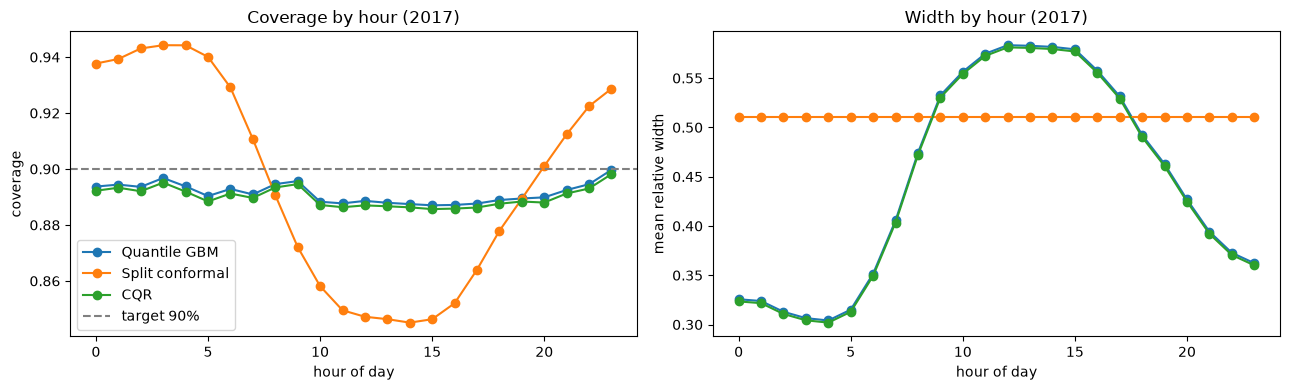

In [5]:
import matplotlib.pyplot as plt

hours = test["hour"].to_numpy()
methods = {"Quantile GBM": (lo_a, hi_a),
           "Split conformal": (lo_b, hi_b),
           "CQR": (lo_c, hi_c)}

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, (lo, hi) in methods.items():
    covered = pd.Series((y >= lo) & (y <= hi))
    width = pd.Series((hi - lo) / scale)
    axes[0].plot(covered.groupby(hours).mean(), marker="o", label=name)
    axes[1].plot(width.groupby(hours).mean(), marker="o", label=name)
axes[0].axhline(0.9, color="gray", ls="--", label="target 90%")
axes[0].set(xlabel="hour of day", ylabel="coverage", title="Coverage by hour (2017)")
axes[1].set(xlabel="hour of day", ylabel="mean relative width", title="Width by hour (2017)")
axes[0].legend()
fig.tight_layout()